<a href="https://colab.research.google.com/github/Tanuja-code125/Applied-ML-Lab/blob/main/ML_Exp6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exp 6: Sentiment Analysis of Restaurant Reviews
**Aim:** Classify reviews as positive/negative using NLP + Naïve Bayes, Logistic Regression, SVM and Random Forest, and compare them using Accuracy, Precision, Recall and F1-Score.

Run the cells top to bottom (Runtime → Run all).

## Step 1: Import libraries

In [ ]:
import re, io
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import nltk
from nltk.stem import PorterStemmer
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)
SEED = 42

## Step 2: Upload the dataset
A file picker appears. Choose `restaurant_reviews_1000.csv` (the `.xls` name is fine; it is really a CSV).

In [ ]:
try:
    from google.colab import files
    up = files.upload()
    df = pd.read_csv(io.BytesIO(next(iter(up.values()))))
except ImportError:           # running outside Colab
    import os; df = pd.read_csv(os.environ["CSV"])
df.head()

Saving restaurant_reviews_1000.csv.xls to restaurant_reviews_1000.csv.xls


,review,sentiment,label
0,I really enjoyed this restaurant; the salad ta...,positive,1
1,I would gladly return because the sandwich was...,positive,1
2,"The meal was pleasant, fresh, and reasonably p...",positive,1
3,I would gladly return because the curry was ou...,positive,1
4,I will not return because the salad was bland ...,negative,0


## Step 3: Explore the data
Check size, missing values, class balance and duplicates.

Shape: (1000, 3)
Missing values: 0
Duplicate reviews: 362
label
1    500
0    500
Name: count, dtype: int64


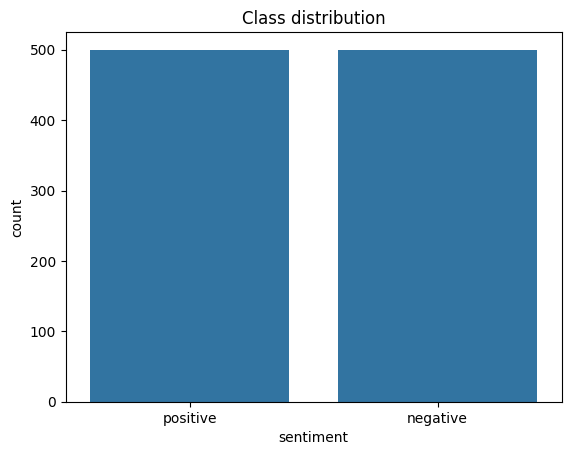

In [ ]:
print("Shape:", df.shape)
print("Missing values:", df.isna().sum().sum())
print("Duplicate reviews:", df['review'].duplicated().sum())
print(df['label'].value_counts())
sns.countplot(x='sentiment', data=df); plt.title("Class distribution"); plt.show()

## Step 4: Text preprocessing (NLP)
Lowercase → remove punctuation → remove stop words → stem.
Negation words (*not, no, never*) are **kept**, because "will not return" is negative.

In [ ]:
try:
    nltk.download('stopwords', quiet=True)
    from nltk.corpus import stopwords
    STOP = set(stopwords.words('english'))
except Exception:
    STOP = set(ENGLISH_STOP_WORDS)
STOP -= {"not", "no", "nor", "never", "cannot"}
stemmer = PorterStemmer()

def clean(text):
    text = re.sub(r"[^a-z\s]", " ", text.lower())
    return " ".join(stemmer.stem(w) for w in text.split() if w not in STOP)

df['clean'] = df['review'].apply(clean)
df[['review', 'clean']].head()

,review,clean
0,I really enjoyed this restaurant; the salad ta...,realli enjoy restaur salad tast outstand
1,I would gladly return because the sandwich was...,would gladli return sandwich wonder servic excel
2,"The meal was pleasant, fresh, and reasonably p...",meal pleasant fresh reason price
3,I would gladly return because the curry was ou...,would gladli return curri outstand servic excel
4,I will not return because the salad was bland ...,not return salad bland servic unaccept


## Step 5: Remove duplicates
Identical reviews in both train and test sets would inflate scores (data leakage), so we drop them **before** splitting.

In [ ]:
before = len(df)
df = df.drop_duplicates(subset='review').reset_index(drop=True)
print(f"{before} -> {len(df)} unique reviews")
print(df['label'].value_counts())

1000 -> 638 unique reviews
label
1    324
0    314
Name: count, dtype: int64


## Step 6: Train / test split (80 / 20)

In [ ]:
X, y = df['clean'], df['label']
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print("Train:", len(Xtr), " Test:", len(Xte))

Train: 510  Test: 128


## Step 7: Feature extraction (TF-IDF)
Turns text into numbers. Using single words + word pairs (bigrams) so phrases like *not good* are captured. The vectorizer is placed inside a Pipeline so it is fitted only on training data.

In [ ]:
def tfidf():
    return TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)

models = {
    "Naive Bayes":         MultinomialNB(alpha=0.5),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=SEED),
    "SVM (Linear)":        LinearSVC(random_state=SEED),
    "Random Forest":       RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1),
}

## Step 8: Train all four models and evaluate

In [ ]:
rows, cms, fitted = [], {}, {}
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
for name, clf in models.items():
    pipe = Pipeline([("tfidf", tfidf()), ("clf", clf)]).fit(Xtr, ytr)
    fitted[name] = pipe
    p = pipe.predict(Xte)
    cv = cross_val_score(Pipeline([("tfidf", tfidf()), ("clf", clf)]), X, y, cv=skf)
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(yte, p), "Precision": precision_score(yte, p),
                 "Recall": recall_score(yte, p), "F1-Score": f1_score(yte, p),
                 "5-Fold CV Acc": cv.mean()})
    cms[name] = confusion_matrix(yte, p)
    print("="*50, "\n", name)
    print(classification_report(yte, p, target_names=["Negative", "Positive"], digits=4))

 Naive Bayes
              precision    recall  f1-score   support

    Negative     1.0000    1.0000    1.0000        63
    Positive     1.0000    1.0000    1.0000        65

    accuracy                         1.0000       128
   macro avg     1.0000    1.0000    1.0000       128
weighted avg     1.0000    1.0000    1.0000       128

 Logistic Regression
              precision    recall  f1-score   support

    Negative     1.0000    1.0000    1.0000        63
    Positive     1.0000    1.0000    1.0000        65

    accuracy                         1.0000       128
   macro avg     1.0000    1.0000    1.0000       128
weighted avg     1.0000    1.0000    1.0000       128

 SVM (Linear)
              precision    recall  f1-score   support

    Negative     1.0000    1.0000    1.0000        63
    Positive     1.0000    1.0000    1.0000        65

    accuracy                         1.0000       128
   macro avg     1.0000    1.0000    1.0000       128
weighted avg     1.0000   

## Step 9: Comparative analysis table

In [ ]:
res = pd.DataFrame(rows).set_index("Model").round(4)
res

,Accuracy,Precision,Recall,F1-Score,5-Fold CV Acc
Model,,,,,
Naive Bayes,1.0,1.0,1.0,1.0,1.0
Logistic Regression,1.0,1.0,1.0,1.0,1.0
SVM (Linear),1.0,1.0,1.0,1.0,1.0
Random Forest,1.0,1.0,1.0,1.0,1.0


## Step 10: Visual comparison

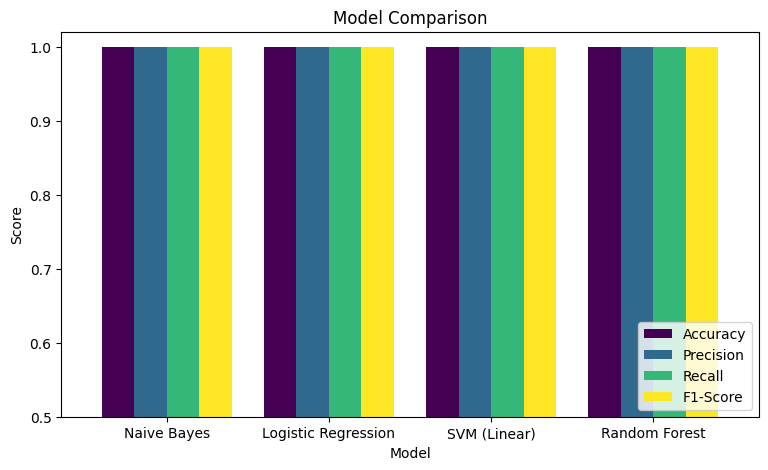

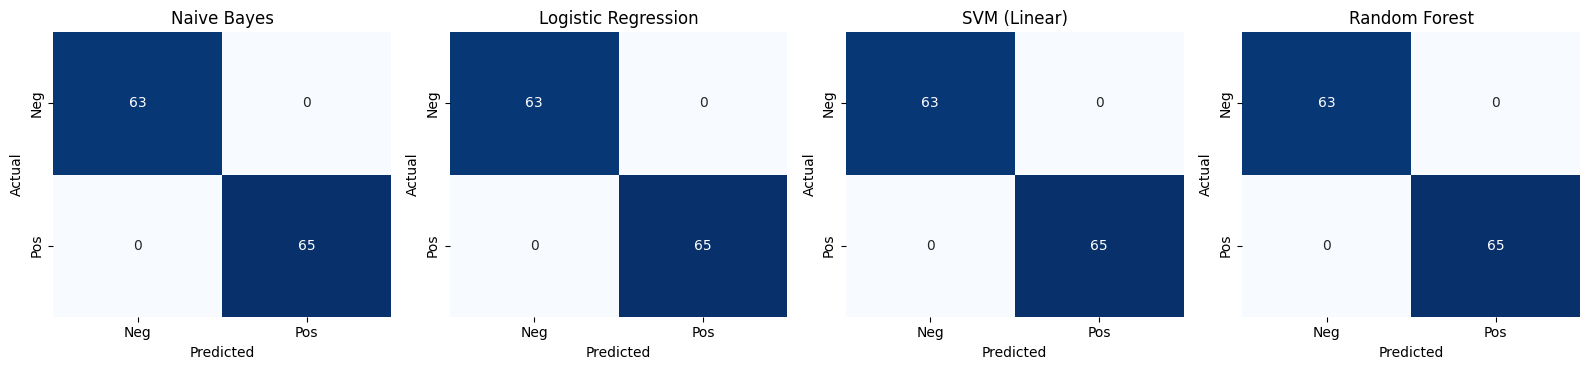

In [ ]:
res[["Accuracy","Precision","Recall","F1-Score"]].plot.bar(figsize=(9,5), width=0.8, colormap="viridis")
plt.title("Model Comparison"); plt.ylabel("Score"); plt.ylim(0.5, 1.02)
plt.xticks(rotation=0); plt.legend(loc="lower right"); plt.show()

fig, axs = plt.subplots(1, 4, figsize=(16, 3.8))
for a, (n, cm) in zip(axs, cms.items()):
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=a,
                xticklabels=["Neg","Pos"], yticklabels=["Neg","Pos"])
    a.set_title(n); a.set_xlabel("Predicted"); a.set_ylabel("Actual")
plt.tight_layout(); plt.show()

## Step 11: Robustness check on new, natural reviews
Every model usually scores ~100% on this dataset because its reviews are built from repeated sentence templates. To compare the models more fairly, test them on 24 hand-written reviews they have never seen.

In [ ]:
ext = [
 ("The pasta was delicious and the waiter was very friendly.",1),("Loved the ambience, will definitely come back!",1),
 ("Best pizza I have had in years, totally worth the price.",1),("Great food, fast service and a cozy atmosphere.",1),
 ("Everything was fresh and the dessert was heavenly.",1),("Staff went out of their way to make us feel welcome.",1),
 ("Fantastic flavors, generous portions, fair prices.",1),("A wonderful dinner, highly recommend this place.",1),
 ("Not bad at all, actually really good soup.",1),("I was impressed by how tasty and well presented everything was.",1),
 ("Superb steak cooked perfectly, lovely service.",1),("Cheap, tasty and quick, I am a fan.",1),
 ("The food was cold and tasteless.",0),("Terrible service, we waited an hour for our order.",0),
 ("Overpriced and disappointing, I will never come back.",0),("The place was dirty and the staff was rude.",0),
 ("Worst burger ever, completely dry and greasy.",0),("Not good, the soup was bland and salty.",0),
 ("Awful experience, the waiter ignored us the whole night.",0),("Slow, noisy and the food was mediocre at best.",0),
 ("I regret coming here, the pasta was soggy and the sauce was bad.",0),("Horrible smell, rude manager, and a long wait.",0),
 ("Nothing special, the food was bland and overpriced.",0),("Unpleasant visit; cold fries and unfriendly service.",0)]
Xe = pd.Series([clean(t) for t,_ in ext]); ye = np.array([l for _,l in ext])
r2 = []
for name, pipe in fitted.items():
    p = pipe.predict(Xe)
    r2.append({"Model": name, "Accuracy": accuracy_score(ye,p), "Precision": precision_score(ye,p,zero_division=0),
               "Recall": recall_score(ye,p), "F1-Score": f1_score(ye,p)})
pd.DataFrame(r2).set_index("Model").round(4)

,Accuracy,Precision,Recall,F1-Score
Model,,,,
Naive Bayes,0.9167,0.9167,0.9167,0.9167
Logistic Regression,0.7917,0.8889,0.6667,0.7619
SVM (Linear),0.7917,0.8889,0.6667,0.7619
Random Forest,0.7500,0.7500,0.7500,0.7500


## Step 12: Try your own review

In [ ]:
def predict(text, model="Naive Bayes"):
    return "Positive" if fitted[model].predict([clean(text)])[0] == 1 else "Negative"

for t in ["The food was amazing and the staff were lovely", "Cold food and very rude service"]:
    print(t, "->", predict(t))

The food was amazing and the staff were lovely -> Positive
Cold food and very rude service -> Negative


## Conclusion
- All four models reach ~100% on the dataset's test split, because the data is highly templated.
- On unseen natural reviews, Naïve Bayes performed best (small sample, so treat as indicative). Compare your own numbers from Step 9 and Step 11.
- **Accuracy** = correct / total; **Precision** = of predicted positives, how many are truly positive; **Recall** = of true positives, how many were found; **F1** = harmonic mean of Precision and Recall.